[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/langchain-ai/langchain-academy/blob/main/module-2/state-schema.ipynb) [![Open in LangChain Academy](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66e9eba12c7b7688aa3dbb5e_LCA-badge-green.svg)](https://academy.langchain.com/courses/take/intro-to-langgraph/lessons/58239426-lesson-1-state-schema)

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🎯 State Schema

**一句话定位**：复习 module 1 的 agent 四件事（`act` / `observe` / `reason` / `persist state`），然后深入讲 LangGraph 定义 state schema 的几种方式。

Module 1 中搭的 agent 能够：
- `act` —— 让模型调用指定工具
- `observe` —— 把工具输出传回模型
- `reason` —— 让模型推理工具输出，决定下一步（再调用工具还是直接回答）
- `persist state` —— 用内存 checkpointer 支持带中断的长对话

并展示了如何用 LangGraph Studio 本地跑，或用 LangGraph Cloud 部署（🆕 两者现已更名：LangGraph Studio → **LangSmith Studio**，LangGraph Cloud/Platform → **LangSmith Deployment**；API 不变）。本节先回顾几种定义 state schema 的方式。

</div>

## Schema

定义 `StateGraph` 时要用到 [state schema](https://docs.langchain.com/oss/python/langgraph/graph-api/#state) —— 它规定了图里流转数据的结构和类型，所有节点都按这个 schema 通信。

LangGraph 对 schema 的定义方式很灵活，支持多种 Python [类型](https://docs.python.org/3/library/stdtypes.html#type-objects) 和校验方式。

## TypedDict

可以用 Python `typing` 模块里的 `TypedDict`，指定 key 和对应的值类型。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**关键洞察**：`TypedDict` 给出的只是**类型提示（type hint）**，供 [mypy](https://github.com/python/mypy) 等静态检查工具或 IDE 在运行前发现潜在类型错误——**运行时完全不校验**，传错了也不会报错。

</div>

In [1]:
from typing_extensions import TypedDict

class TypedDictState(TypedDict):
    foo: str
    bar: str

更精确地约束取值范围，可以用 `Literal` 类型提示。下面例子里，`mood` 只能是 `"happy"` 或 `"sad"`。

In [2]:
from typing import Literal

class TypedDictState(TypedDict):
    name: str
    mood: Literal["happy","sad"]

把定义好的 state 类（这里是 `TypedDictState`）直接传给 `StateGraph` 即可使用。可以把每个 state key 都看作图里的一个“channel”——正如 module 1 讨论过的，每个节点默认会覆盖它返回的那个 key / channel 的值。

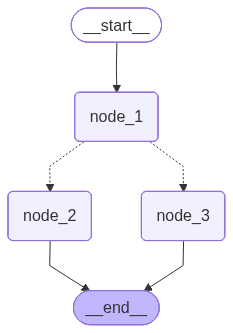

In [3]:
import random
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

def node_1(state):
    print("---Node 1---")
    return {"name": state['name'] + " is ... "}

def node_2(state):
    print("---Node 2---")
    return {"mood": "happy"}

def node_3(state):
    print("---Node 3---")
    return {"mood": "sad"}

def decide_mood(state) -> Literal["node_2", "node_3"]:
        
    # Here, let's just do a 50 / 50 split between nodes 2, 3
    if random.random() < 0.5:

        # 50% of the time, we return Node 2
        return "node_2"
    
    # 50% of the time, we return Node 3
    return "node_3"

# Build graph
builder = StateGraph(TypedDictState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

# Logic
builder.add_edge(START, "node_1")
builder.add_conditional_edges("node_1", decide_mood)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)

# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

因为 state 本质是个 dict，所以调用图时直接传一个 dict 来设置 `name` 的初始值即可。

In [4]:
graph.invoke({"name": "Lance"})

---Node 1---
---Node 2---


{'name': 'Lance is ... ', 'mood': 'happy'}

## Dataclass

Python 的 [dataclasses](https://docs.python.org/3/library/dataclasses.html) 是[另一种定义结构化数据](https://www.datacamp.com/tutorial/python-data-classes)的方式，语法更简洁，适合主要用来存数据的类。

In [5]:
from dataclasses import dataclass

@dataclass
class DataclassState:
    name: str
    mood: Literal["happy","sad"]

访问 `dataclass` 的字段时，`node_1` 里取值方式要相应调整：

- `dataclass` 用 `state.name`（属性访问），而不是 `TypedDict` 那种 `state["name"]`（下标访问）

有个容易忽略的细节：节点内部依然**返回一个 dict** 来做 state 更新。

<div class="dark-info" style="background:#1e293b; color:#e2e8f0; padding:12px 24px; border-left:4px solid #60a5fa; border-radius:4px; width:97%;"><style>.dark-info strong{color:#fbbf24;}</style>

**为什么可以这样**：LangGraph 会把 state 对象的每个 key 分开存储。节点返回的对象只需要 key（属性）跟 state 里的对得上即可——`dataclass` 有 `name` 这个字段，所以哪怕节点返回的是 dict，也能正常更新它，跟 `TypedDict` 时的写法一样。

</div>

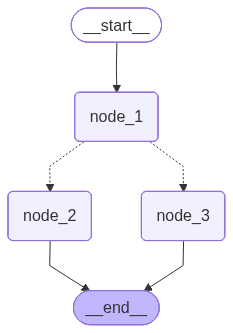

In [6]:
def node_1(state):
    print("---Node 1---")
    return {"name": state.name + " is ... "}

# Build graph
builder = StateGraph(DataclassState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

# Logic
builder.add_edge(START, "node_1")
builder.add_conditional_edges("node_1", decide_mood)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)

# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

用 `dataclass` 调用图时，同样是设置每个 key / channel 的初始值。

In [9]:
graph.invoke(DataclassState(name="Lance",mood="sad"))

---Node 1---
---Node 3---


{'name': 'Lance is ... ', 'mood': 'sad'}

<div class="dark-info" style="background:#1e293b; color:#e2e8f0; padding:12px 24px; border-left:4px solid #60a5fa; border-radius:4px; width:97%;"><style>.dark-info strong{color:#fbbf24;}</style>

🆕 这里传 `mood="sad"` 只是因为 dataclass 字段**没有默认值**、构造时必须给；它随后会被 `node_2` / `node_3` 覆盖，对结果没有影响（多跑几次会看到 happy / sad 交替）。给字段加默认值 `mood: Literal["happy","sad"] = "happy"`，就能像 TypedDict 一样只传 `name`。

</div>

## Pydantic

`TypedDict` 和 `dataclass` 都只提供类型提示，**不在运行时强制校验类型**——这意味着可能悄悄传入非法值而不报错。

例如，即使类型提示写的是 `mood: list[Literal["happy","sad"]]`，仍然可以把 `mood` 设成 `"mad"` 而不触发任何错误。

In [8]:
dataclass_instance = DataclassState(name="Lance", mood="mad")

[Pydantic](https://docs.pydantic.dev/latest/api/base_model/) 是基于 Python 类型注解的数据校验与配置管理库。

由于自带运行时校验能力，Pydantic 特别适合[用来定义 LangGraph 的 state schema](https://docs.langchain.com/oss/python/langgraph/use-graph-api#use-pydantic-models-for-graph-state)——它能在运行时真正检查数据是否符合指定的类型和约束。

In [10]:
from pydantic import BaseModel, field_validator, ValidationError

class PydanticState(BaseModel):
    name: str
    mood: str # "happy" or "sad" 

    @field_validator('mood')
    @classmethod
    def validate_mood(cls, value):
        # Ensure the mood is either "happy" or "sad"
        if value not in ["happy", "sad"]:
            raise ValueError("Each mood must be either 'happy' or 'sad'")
        return value

try:
    state = PydanticState(name="John Doe", mood="mad")
except ValidationError as e:
    print("Validation Error:", e)

Validation Error: 1 validation error for PydanticState
mood
  Value error, Each mood must be either 'happy' or 'sad' [type=value_error, input_value='mad', input_type=str]
    For further information visit https://errors.pydantic.dev/2.12/v/value_error


`PydanticState` 可以无缝用在图里。

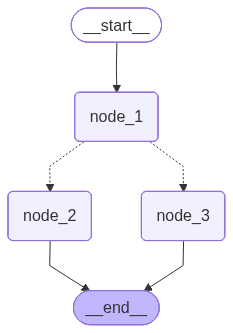

In [11]:
# Build graph
builder = StateGraph(PydanticState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

# Logic
builder.add_edge(START, "node_1")
builder.add_conditional_edges("node_1", decide_mood)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)

# Add
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
graph.invoke(PydanticState(name="Lance", mood="sad"))

---Node 1---
---Node 3---


{'name': 'Lance is ... ', 'mood': 'sad'}

---
### 📝 笔记:LangGraph 定义 State Schema 的 3 种方式

| 方式 | 写法 | 运行时校验 | 取值方式 |
|---|---|---|---|
| **TypedDict** | `class S(TypedDict): foo: str` | ❌ 不校验,只是类型提示 | `state["foo"]` |
| **dataclass** | `@dataclass class S: foo: str` | ❌ 不校验 | `state.foo` |
| **Pydantic `BaseModel`** | `class S(BaseModel): foo: str` | ✅ 运行时真正校验(配合 `field_validator` 可自定义规则) | `state.foo` |

- 三种都能直接传给 `StateGraph(S)` 使用,节点内部统一**返回 dict** 来更新 state(即使 state 本身是 dataclass/Pydantic)。
- 只有 Pydantic 会在赋值不合法时真正抛 `ValidationError`;`TypedDict`/`dataclass` 传错值不会报错,只是 IDE/mypy 可能提示。
- 默认优先用 `TypedDict`,需要**强校验**(比如限制取值范围)时才用 Pydantic。
